# Stage 05 verification: before vs. after the 10-member-ensemble-mean PGW perturbation

Checks whatever `04_apply_perturbation.py` has actually produced under `config.PERTURBED_IM_DIR` against the real ERA5 WPS intermediate files it perturbed. Test dates are **auto-discovered** from the perturbed-file directory (not hardcoded), so this notebook stays correct as more years/months get run.

Three independent checks, each stronger than the last:

1. **Structural integrity** -- every field/record *not* in the perturbation set is byte-identical between original and perturbed files; only the expected fields/records changed.
2. **Quantitative correctness** -- the applied delta (`perturbed - original`) matches the stage-03 delta file exactly (modulo the documented RH clip and SST floor).
3. **Physical plausibility** -- maps and vertical profiles of the applied delta reproduce the expected PGW/climate-change signature (tropospheric warming + geopotential expansion, stratospheric cooling + contraction), driven here by the 10-member LENS2 ensemble-mean warming signal rather than a single member's.

Also verifies the separate periodic SST-update stream (`ERA5_SST:*` -> `SST_UPDATE:*`), which uses a different file layout/land-mask than the main archive.

Run with the `Python (casper_2023)` kernel (same env/config as the pipeline itself).

In [1]:
import sys
sys.path.insert(0, "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10")  # so `import config`/`lib` below resolve

import importlib.util
import glob
from pathlib import Path

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import config              # this project's paths/constants (grid, periods, field lists, ...)
import lib.wps_intermediate as wps  # reader/writer for the binary WPS intermediate-file format

# Load 04_apply_perturbation.py as a module via importlib rather than a normal `import`,
# because its filename starts with a digit ("04_...") so `import 04_apply_perturbation`
# is not valid Python syntax. Reusing it directly -- instead of re-typing its constants
# and functions here -- means this notebook can't silently drift from what stage 04
# actually does: SST_FLOOR_K, SST_FILL_THRESHOLD, load_ocean_mask(), and the regexes
# that recognize ERA5:*/ERA5_SST:* filenames all come from the one place that matters.
_spec = importlib.util.spec_from_file_location(
    "apply_pgw", "/glade/u/home/mingge/MPAS/MPAS_LENS2_PGW_ENS10/04_apply_perturbation.py")
apply_pgw = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(apply_pgw)

ORIG_DIR = config.ERA5_IM_DIR       # real ERA5 WPS intermediate files (never modified by stage 04)
PERT_DIR = config.PERTURBED_IM_DIR  # stage 04's perturbed copies, written alongside (not over) the originals
print("originals: ", ORIG_DIR)
print("perturbed: ", PERT_DIR)

originals:  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas
perturbed:  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean


## Auto-discover what stage 04 has actually produced

Main `ERA5:*` archive test dates, plus the separate `SST_<year>/ERA5_SST:*` -> `SST_UPDATE:*` stream.

In [2]:
# Main-stream files: PERT_DIR holds one "ERA5:<date>" per date stage 04 processed.
# _IM_NAME_RE (borrowed from apply_pgw) matches only the exact "ERA5:YYYY-MM-DD_HH" naming,
# so any unrelated sidecar file that happens to share the "ERA5:" prefix is excluded.
pert_files = sorted(PERT_DIR.glob(f"{config.ERA5_IM_PREFIX}:*"))
test_dates = [f.name.split(":")[1] for f in pert_files if apply_pgw._IM_NAME_RE.match(f.name)]
print(f"{len(test_dates)} main-stream test files:")
for d in test_dates:
    print(" ", d)

# SST-update stream: a different file layout, one record per file, under a per-year
# subdirectory (e.g. PERT_DIR/SST_1984/SST_UPDATE:1984-06-01_00).
_sst_pattern = str(PERT_DIR / "SST_*" / f"{apply_pgw._SST_UPDATE_PREFIX}:*")
sst_pert_files = sorted(Path(p) for p in glob.glob(_sst_pattern))
print(f"\n{len(sst_pert_files)} SST-update test files (first/last shown):")
for f in (sst_pert_files[:3] + (["..."] if len(sst_pert_files) > 6 else []) + sst_pert_files[-3:]):
    print(" ", f)

6 main-stream test files:
  1984-06-01_00
  1984-06-02_00
  1984-06-03_00
  1984-06-04_00
  1984-06-05_00
  1984-06-06_00

184 SST-update test files (first/last shown):
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean/SST_1984/SST_UPDATE:1984-06-01_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean/SST_1984/SST_UPDATE:1984-06-02_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean/SST_1984/SST_UPDATE:1984-06-03_00
  ...
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean/SST_1984/SST_UPDATE:1984-11-29_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean/SST_1984/SST_UPDATE:1984-11-30_00
  /glade/campaign/mmm/c3we/mingge/wpsv4.5_mpas_LENS2PGW_ens10mean/SST_1984/SST_UPDATE:1984-12-01_00


## 1. Structural integrity

For every test file: same record count and order, same field/level list. Every record's slab must be **byte-identical** to the original *unless* it's one of the fields stage 04 is documented to touch (`GHT`, `TT`, `RH` at pressure levels, `SKINTEMP`, `SST`-over-ocean). In particular the surface-sentinel (`xlvl=200100`) 2 m `TT` / 2 m `RH` records, and everything else (`UU`, `VV`, `PSFC`, `PMSL`, soil, `SEAICE`, `SNOW`, `LANDSEA`, `SOILHGT`, ...), must be untouched.

In [3]:
PERTURBED_3D = set(config.PERTURB_FIELDS_3D)           # {GHT, TT, RH} -- 3-D, one slab per pressure level
PERTURBED_SFC = set(config.PERTURB_FIELDS_SFC.keys())  # {SST, SKINTEMP} -- single 2-D surface slab

def key(rec):
    # (field name, level) identifies a record independent of its position in the file,
    # so record order can be compared robustly between the original and perturbed files.
    return (rec.field, round(rec.xlvl, 3))

def check_file(date):
    """Read the original and perturbed copy of one date and compare record-by-record."""
    orig = wps.read_file(ORIG_DIR / f"{config.ERA5_IM_PREFIX}:{date}")
    pert = wps.read_file(PERT_DIR / f"{config.ERA5_IM_PREFIX}:{date}")

    # stage 04 must not add, drop, or reorder records -- only mutate slab *values* in place
    assert len(orig) == len(pert), f"{date}: record count changed ({len(orig)} vs {len(pert)})"
    assert [key(r) for r in orig] == [key(r) for r in pert], f"{date}: field/level order changed"

    touched, untouched_changed = [], []
    for ro, rp in zip(orig, pert):
        changed = not np.array_equal(ro.slab, rp.slab)  # exact float32 equality -- no perturbation means no change at all
        is_sfc_sentinel = ro.xlvl == config.ERA5_SURFACE_LEVEL_PA
        # "perturbable" here means: a 3-D field at a real pressure level (not the 2 m/10 m
        # surface-sentinel records that share the same field name), or one of the two
        # surface fields (SST/SKINTEMP) which have no vertical-level ambiguity at all.
        expected_perturbable = (
            (ro.field in PERTURBED_3D and not is_sfc_sentinel) or
            (ro.field in PERTURBED_SFC)
        )
        if changed:
            touched.append(key(ro))
            if not expected_perturbable:
                # a record outside the documented perturbation set changed -- that's a bug,
                # not a legitimate side effect (e.g. it would mean SEAICE or UU got corrupted)
                untouched_changed.append(key(ro))

    return dict(date=date, n_records=len(orig), n_touched=len(touched),
                fields_present={r.field for r in orig},
                unexpected_changes=untouched_changed, orig=orig, pert=pert)

results = [check_file(d) for d in test_dates]
for r in results:
    status = "OK" if not r["unexpected_changes"] else "FAIL"
    print(f"{r['date']}: {r['n_touched']:3d}/{r['n_records']} records touched  [{status}]  "
          f"fields={sorted(r['fields_present'])}")
    if r["unexpected_changes"]:
        print("   unexpected changes in:", r["unexpected_changes"])

assert all(not r["unexpected_changes"] for r in results), "a field outside the perturbation set was modified"

# Sanity print, not an assertion: the touched-record count can legitimately differ by one
# between dates, because the main-stream ERA5:* files only carry an SST record on some
# days (see section 2) -- so don't assume a fixed count and flag a spread as automatically wrong.
touched_counts = {r["date"]: r["n_touched"] for r in results}
print(f"\ntouched-record counts by date: {touched_counts}")
if len(set(touched_counts.values())) > 1:
    print("(not uniform -- expected: files that carry an SST record touch one more than files that don't;"
          " see fields_present above and the SST check in section 2)")

1984-06-01_00: 112/204 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'ST000007', 'ST007028', 'ST028100', 'ST100289', 'TT', 'UU', 'VV']
1984-06-02_00: 113/242 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'SPECHUMD', 'SST', 'ST000007', 'ST007028', 'ST028100', 'ST100289', 'TT', 'UU', 'VV']
1984-06-03_00: 113/242 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'SPECHUMD', 'SST', 'ST000007', 'ST007028', 'ST028100', 'ST100289', 'TT', 'UU', 'VV']
1984-06-04_00: 113/242 records touched  [OK]  fields=['GHT', 'LANDSEA', 'PMSL', 'PSFC', 'RH', 'SEAICE', 'SKINTEMP', 'SM000007', 'SM007028', 'SM028100', 'SM100289', 'SNOW', 'SOILHGT', 'SPECHUMD', 'SST', 'ST000007', '

## 2. Quantitative cross-check against the stage-03 delta file

`perturbed - original` should equal the stage-03 `DELTA_DIR/<month>.nc` value at the matching field/level, exactly (both are float32, single add, no reason for rounding drift) -- except:
- **RH**: clipped to `[0, 100]` after adding the delta, so cells that would go out of bounds legitimately differ from the raw delta.
- **SST**: only perturbed over ocean (not land-fill sentinel), and floored at 271 K -- checked separately, only over cells where neither exception applies.

Deltas are loaded per month actually needed, rather than assuming a single hardcoded month.

In [4]:
# The delta (future-minus-current ensemble-mean climatology) varies by calendar month, so
# figure out which month(s) our test files actually fall in and load only those -- each
# ERA5 file's own hdate (e.g. "1984-06-01_00") tells us its month via the "MM" slice [5:7].
months_needed = sorted({int(r["orig"][0].hdate[5:7]) for r in results if r["orig"]})
print("months present in test files:", months_needed)

deltas = {}
for m in months_needed:
    with xr.open_dataset(config.DELTA_DIR / f"{m:02d}.nc") as ds:
        deltas[m] = {k: ds[k].values for k in ["lev_pa", "GHT", "TT", "RH", "SST", "SKINTEMP"]}

# Not every ERA5:* file carries an SST record (it's only archived some days) -- both
# groups below are expected/legitimate, just noted so the SST check further down makes sense.
sst_dates = [r["date"] for r in results if "SST" in r["fields_present"]]
no_sst_dates = [r["date"] for r in results if "SST" not in r["fields_present"]]
print(f"SST record present in: {sst_dates}")
print(f"SST record absent in:  {no_sst_dates}")
print("(both are legitimate -- ERA5:* only carries an SST record on some days; the periodic-SST-update\n"
      " stream, section 6 below, is the separate ERA5_SST:* prefix. Either way, when SST *is* present\n"
      " in an ERA5:* file, stage 04 perturbs it -- checked below.)")

months present in test files: [6]
SST record present in: ['1984-06-02_00', '1984-06-03_00', '1984-06-04_00', '1984-06-05_00', '1984-06-06_00']
SST record absent in:  ['1984-06-01_00']
(both are legitimate -- ERA5:* only carries an SST record on some days; the periodic-SST-update
 stream, section 6 below, is the separate ERA5_SST:* prefix. Either way, when SST *is* present
 in an ERA5:* file, stage 04 perturbs it -- checked below.)


In [5]:
SST_FLOOR_K = apply_pgw.SST_FLOOR_K              # 271 K seawater-freezing floor applied after perturbing SST
SST_FILL_THRESHOLD = apply_pgw.SST_FILL_THRESHOLD  # below this, an SST record's value means "land, not ocean"

def cross_check(r):
    """For one date's records, compare (perturbed - original) against the stage-03 delta
    at the matching field/level, and return the worst-case absolute error per field."""
    month = int(r["orig"][0].hdate[5:7])
    lev_pa = deltas[month]["lev_pa"]
    max_abs_err = {}
    for ro, rp in zip(r["orig"], r["pert"]):
        is_sfc_sentinel = ro.xlvl == config.ERA5_SURFACE_LEVEL_PA
        applied = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)  # what stage 04 actually added

        if ro.field in PERTURBED_3D and not is_sfc_sentinel:
            # match this record's pressure level to the closest level in the delta file
            # (both come from the same 37-level ERA5 standard set, so this should be exact)
            idx = int(np.argmin(np.abs(lev_pa - ro.xlvl)))
            expected = deltas[month][ro.field][idx].astype(np.float64)
            if ro.field == "RH":
                # only compare cells that stayed inside [0, 100] -- clipped cells legitimately
                # deviate from the raw delta by construction, not because of a bug
                unclipped = (rp.slab > 0.0) & (rp.slab < 100.0)
                err = np.abs(applied - expected)[unclipped]
            else:
                err = np.abs(applied - expected)
            if err.size:
                max_abs_err.setdefault(ro.field, 0.0)
                max_abs_err[ro.field] = max(max_abs_err[ro.field], float(err.max()))
        elif ro.field == "SKINTEMP":
            # perturbed everywhere (land + ocean), no clipping/flooring -- should match exactly
            expected = deltas[month]["SKINTEMP"].astype(np.float64)
            err = np.abs(applied - expected)
            max_abs_err["SKINTEMP"] = float(err.max())
        elif ro.field == "SST":
            expected = deltas[month]["SST"].astype(np.float64)
            ocean = ro.slab > SST_FILL_THRESHOLD
            land = ~ocean
            # land-fill sentinel cells must be completely untouched (SST is meaningless over land)
            assert np.array_equal(ro.slab[land], rp.slab[land]), f"{r['date']}: SST land fill was modified"
            # ocean cells that didn't hit the 271 K floor: applied delta must match stage-03 exactly
            not_floored = rp.slab > SST_FLOOR_K
            cmp_mask = ocean & not_floored
            err = np.abs(applied - expected)[cmp_mask]
            if err.size:
                max_abs_err["SST"] = float(err.max())
            # ocean cells that DID hit the floor: their perturbed value must sit exactly at 271 K,
            # not be compared against the raw delta (which would legitimately overshoot the floor)
            floored = ocean & ~not_floored
            if floored.any():
                assert np.allclose(rp.slab[floored], SST_FLOOR_K), \
                    f"{r['date']}: SST floor-clamped cells not at {SST_FLOOR_K} K"
    return max_abs_err

all_errs = {r["date"]: cross_check(r) for r in results}
for d, errs in all_errs.items():
    print(d, errs)

# Worst case across every test date, per field -- should be tiny (float32 round-trip noise
# from a single add), not zero, since both original and delta are float32 to begin with.
worst = {f: max((e.get(f, 0.0) for e in all_errs.values()), default=0.0)
         for f in ["GHT", "TT", "RH", "SKINTEMP", "SST"]}
print("\nworst-case |applied - stage03 delta| across all test files:", worst)
assert all(v < 1e-2 for v in worst.values()), "applied perturbation does not match the stage-03 delta"

# Guard against a silently-vacuous pass: if no test date happened to carry an SST record,
# the SST branch above would never run and "SST" would never appear in `worst`, which
# would look identical to "SST checked and matched" unless we assert it was exercised.
sst_actually_checked = any("SST" in errs for errs in all_errs.values())
assert sst_actually_checked, "expected at least one test file with an SST record to actually be checked"
print("PASS: applied deltas match the stage-03 delta file within float32 tolerance, including SST "
      f"(checked in {[d for d in all_errs if 'SST' in all_errs[d]]}).")

1984-06-01_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SKINTEMP': 1.52587890625e-05}
1984-06-02_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-03_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-04_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-05_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}
1984-06-06_00 {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SST': 1.52587890625e-05, 'SKINTEMP': 1.52587890625e-05}

worst-case |applied - stage03 delta| across all test files: {'GHT': 0.001953125, 'TT': 1.52587890625e-05, 'RH': 3.814697265625e-06, 'SKINTEMP': 1.52587890625e-05, 'SST

## 3. Maps: before / after / difference

One representative date and level (`TT`, `GHT`, `RH` @ 850 hPa, `SKINTEMP`), plus `SST` on a date that carries it (land masked out -- SST is only meaningful over ocean).

A per-level extrema/NaN check on the full 3D stage-03 delta field for `TT`/`GHT`/`RH` follows, to catch any corrupted or missing values before trusting the maps above.

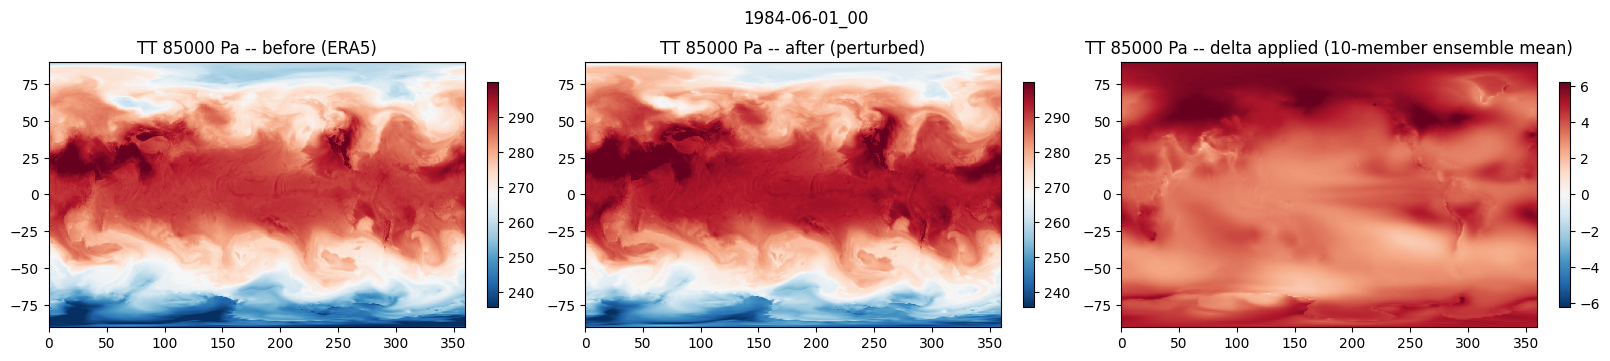

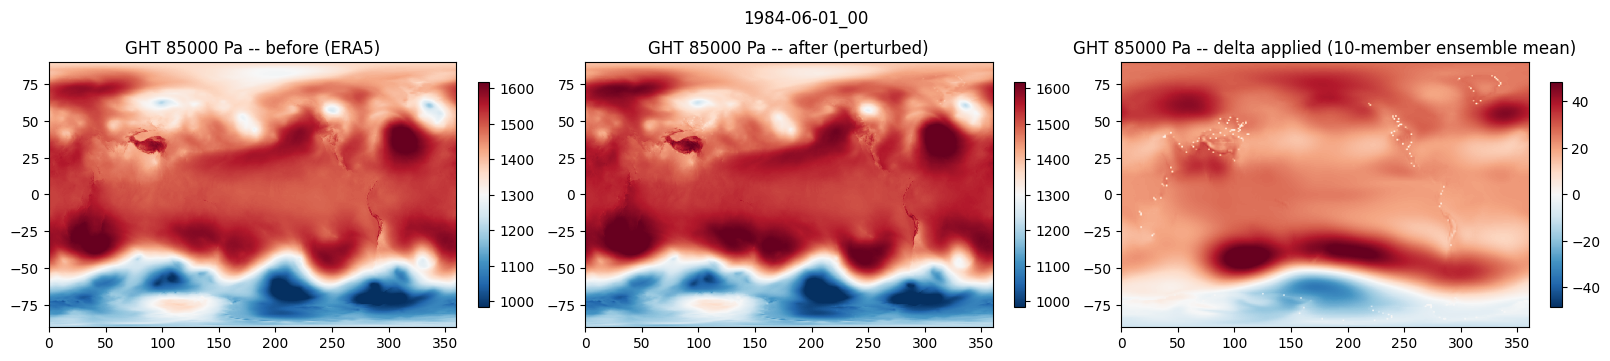

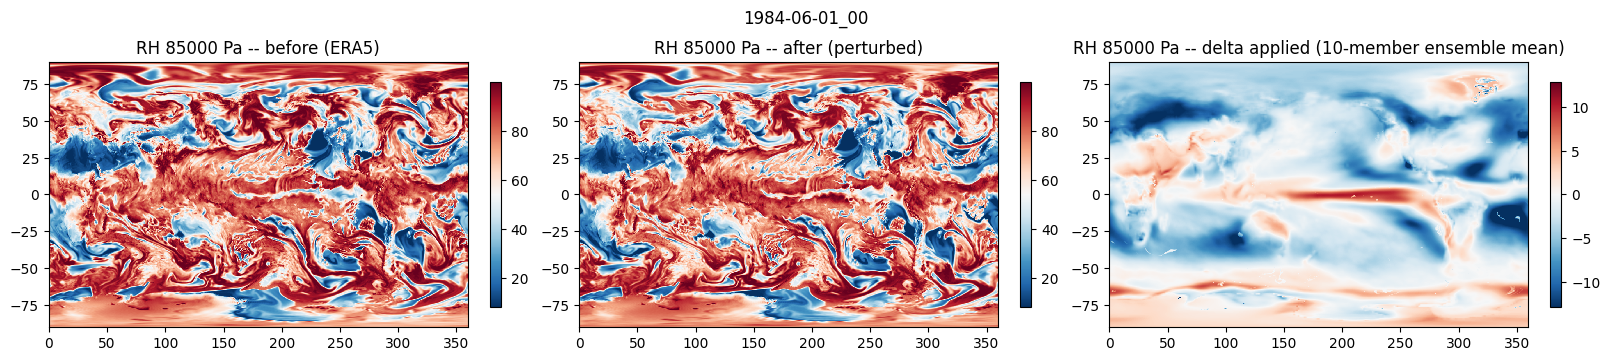

In [6]:
date0 = test_dates[0]                       # one representative date is enough for a visual spot-check
orig0, pert0 = results[0]["orig"], results[0]["pert"]
lat, lon = config.ERA5_LAT, config.ERA5_LON  # the real ERA5 grid (721x1440, -90..90 / 0..359.75)

def find(recs, field, xlvl):
    """Look up a single record by (field, level) out of a file's record list."""
    for r in recs:
        if r.field == field and abs(r.xlvl - xlvl) < 1.0:
            return r
    raise KeyError((field, xlvl))

def plot_before_after_diff(field, xlvl, cmap="RdBu_r", diff_cmap="RdBu_r"):
    """Three side-by-side maps: raw ERA5, perturbed, and the difference (= the applied delta)."""
    ro = find(orig0, field, xlvl)
    rp = find(pert0, field, xlvl)
    d = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)

    fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
    # before/after share one color scale (percentile-clipped) so they're visually comparable
    vmin, vmax = np.nanpercentile(ro.slab, [1, 99])
    for ax, data, title in zip(axes[:2], [ro.slab, rp.slab], ["before (ERA5)", "after (perturbed)"]):
        im = ax.pcolormesh(lon, lat, data, vmin=vmin, vmax=vmax, cmap=cmap, shading="auto")
        ax.set_title(f"{field} {xlvl:.0f} Pa -- {title}")
        fig.colorbar(im, ax=ax, shrink=0.85)
    # the difference panel gets its own symmetric color scale centered on zero
    dmax = np.nanpercentile(np.abs(d), 99)
    im = axes[2].pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap=diff_cmap, shading="auto")
    axes[2].set_title(f"{field} {xlvl:.0f} Pa -- delta applied (10-member ensemble mean)")
    fig.colorbar(im, ax=axes[2], shrink=0.85)
    fig.suptitle(f"{date0}", y=1.08)
    plt.show()

plot_before_after_diff("TT", 85000.0)   # 850 hPa temperature
plot_before_after_diff("GHT", 85000.0)  # 850 hPa geopotential height
plot_before_after_diff("RH", 85000.0)   # 850 hPa relative humidity

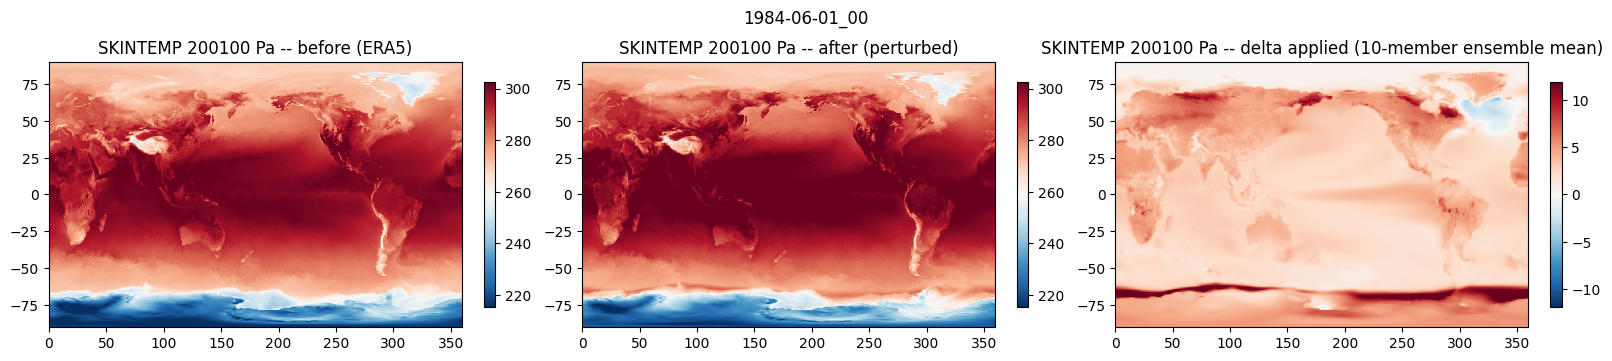

In [7]:
plot_before_after_diff("SKINTEMP", config.ERA5_SURFACE_LEVEL_PA)  # skin temperature (land + ocean)

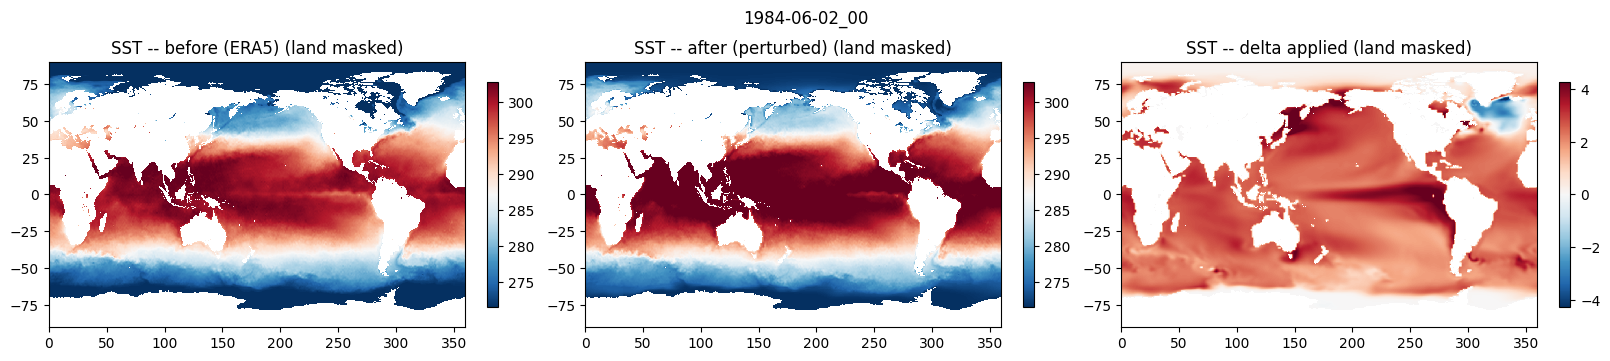

In [8]:
# date0 may not carry an SST record (see section 2) -- use the first test date that does.
assert sst_dates, "no main-stream test date carries an SST record"
sst_date = sst_dates[0]
sst_idx = test_dates.index(sst_date)
orig_sst, pert_sst = results[sst_idx]["orig"], results[sst_idx]["pert"]

ro = find(orig_sst, "SST", config.ERA5_SURFACE_LEVEL_PA)
rp = find(pert_sst, "SST", config.ERA5_SURFACE_LEVEL_PA)
land = ro.slab <= SST_FILL_THRESHOLD          # land-fill sentinel cells -- not real SST, mask them out
d = np.where(land, np.nan, rp.slab.astype(np.float64) - ro.slab.astype(np.float64))
before = np.where(land, np.nan, ro.slab)
after = np.where(land, np.nan, rp.slab)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
vmin, vmax = np.nanpercentile(before, [1, 99])
for ax, data, title in zip(axes[:2], [before, after], ["before (ERA5)", "after (perturbed)"]):
    im = ax.pcolormesh(lon, lat, data, vmin=vmin, vmax=vmax, cmap="RdBu_r", shading="auto")
    ax.set_title(f"SST -- {title} (land masked)")
    fig.colorbar(im, ax=ax, shrink=0.85)
dmax = np.nanpercentile(np.abs(d), 99)
im = axes[2].pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap="RdBu_r", shading="auto")
axes[2].set_title("SST -- delta applied (land masked)")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.suptitle(f"{sst_date}", y=1.08)
plt.show()

In [9]:
# extrema / NaN check on the full stage-03 delta field, per pressure level
month0 = int(orig0[0].hdate[5:7])
for field in ["TT", "GHT", "RH"]:
    dT = deltas[month0][field]
    print(f"Variable: {field}")
    for i, lv in enumerate(deltas[month0]["lev_pa"]):
        level = dT[i]
        print(f"{lv / 100:7.0f} hPa: min={float(np.nanmin(level)):+.2f}  max={float(np.nanmax(level)):+.2f}  "
              f"mean={float(np.nanmean(level)):+.2f}  NaN={int(np.isnan(level).sum())}")
    print()


Variable: TT
      1 hPa: min=-10.85  max=-5.85  mean=-9.18  NaN=0
      2 hPa: min=-10.85  max=-5.85  mean=-9.18  NaN=0
      3 hPa: min=-10.85  max=-5.85  mean=-9.18  NaN=0
      5 hPa: min=-10.26  max=-5.53  mean=-8.71  NaN=0
      7 hPa: min=-9.73  max=-5.19  mean=-8.20  NaN=0
     10 hPa: min=-8.84  max=-4.49  mean=-7.33  NaN=0
     20 hPa: min=-6.67  max=-3.13  mean=-5.54  NaN=0
     30 hPa: min=-5.72  max=-2.34  mean=-4.39  NaN=0
     50 hPa: min=-4.60  max=-0.55  mean=-2.30  NaN=0
     70 hPa: min=-3.07  max=+2.40  mean=-0.51  NaN=0
    100 hPa: min=-2.53  max=+5.38  mean=+1.40  NaN=0
    125 hPa: min=-2.25  max=+5.74  mean=+1.90  NaN=0
    150 hPa: min=-2.21  max=+6.18  mean=+2.10  NaN=0
    175 hPa: min=-1.50  max=+6.84  mean=+2.37  NaN=0
    200 hPa: min=-0.22  max=+6.89  mean=+2.75  NaN=0
    225 hPa: min=+0.44  max=+6.81  mean=+3.26  NaN=0
    250 hPa: min=+0.98  max=+6.65  mean=+3.70  NaN=0
    300 hPa: min=+1.73  max=+6.51  mean=+4.28  NaN=0
    350 hPa: min=+2.02  max=+

## 3b. Multi-level delta maps -- smooth, large-scale climate-change signal check

One row per variable -- `TT` (temperature) at 850/500/200 hPa, `GHT` (geopotential
height) at 500/200 hPa, `RH` (relative humidity) at 850/500 hPa -- so all seven
delta-only maps can be scanned together, grouped by field. A PGW-consistent delta
should look like a **smooth, large-scale** pattern (e.g. broad tropical/subtropical
structure, land-sea contrast, amplification toward high latitudes or aloft) -- not
pixel-scale noise, stripes, or a corrupted field.


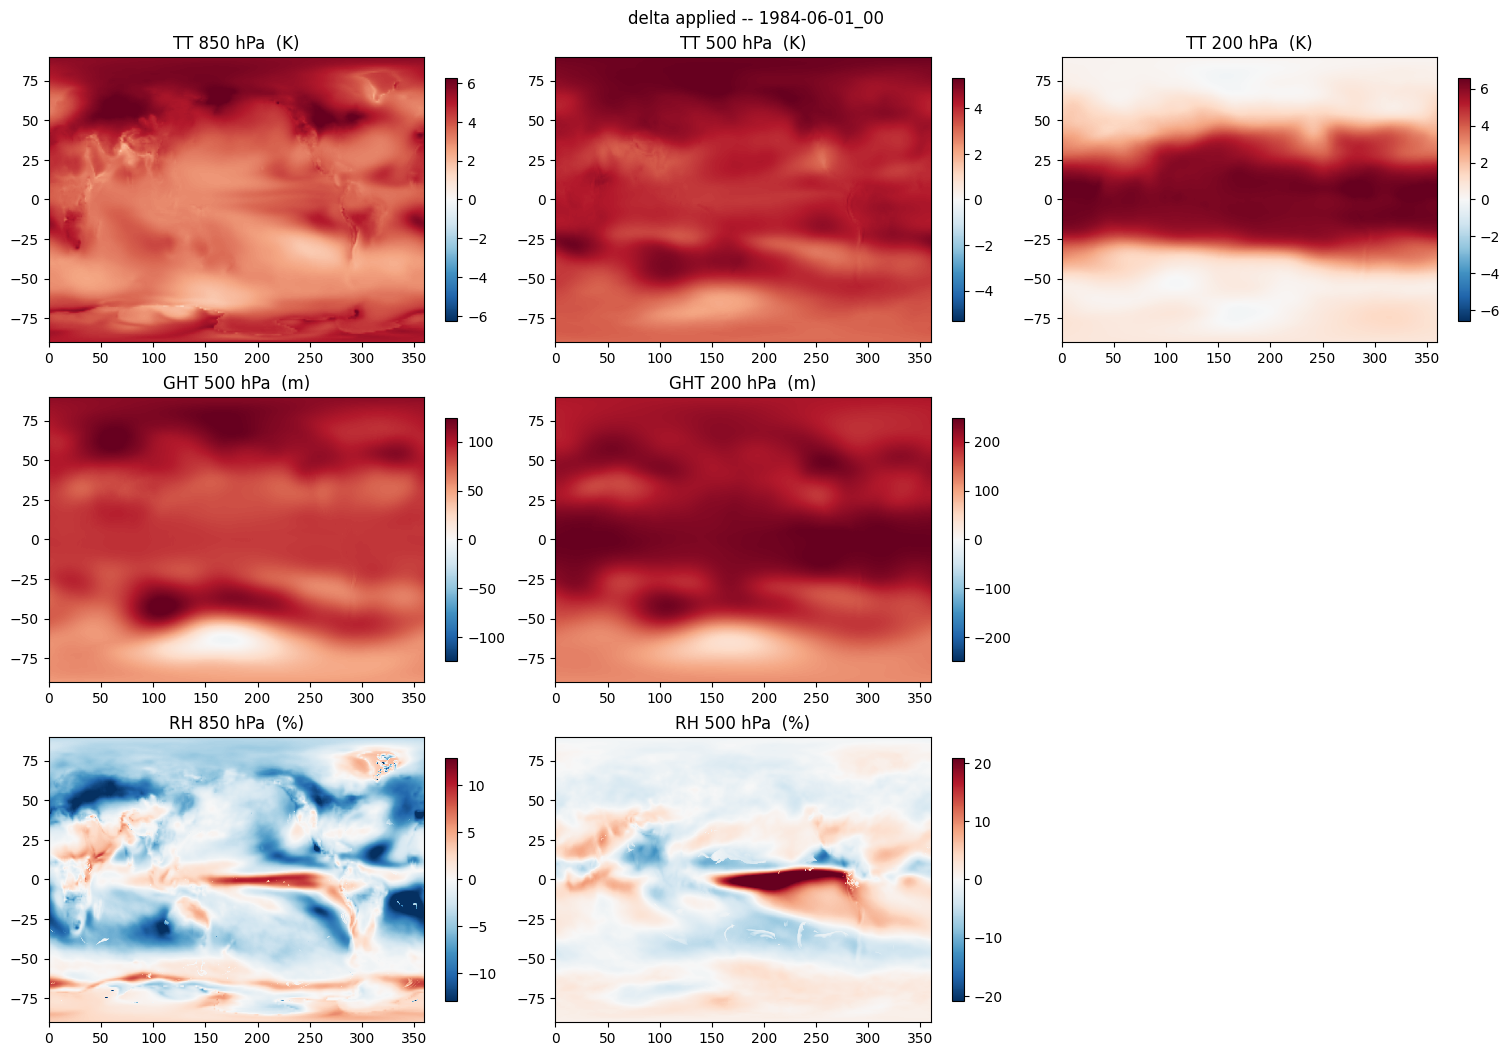

In [10]:
def plot_delta_maps(orig, pert, rows, date_label, suptitle_suffix=""):
    """rows: list of rows, each row a list of (field, xlvl_pa, unit) sharing one
    variable per row (e.g. a TT row, a GHT row, an RH row) -- deliberately omits
    before/after (see section 3 above for those) so all levels/fields can be
    scanned together for smoothness."""
    ncols = max(len(row) for row in rows)
    nrows = len(rows)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows),
                              constrained_layout=True, squeeze=False)
    for row_axes, row in zip(axes, rows):
        for ax, (field, xlvl, unit) in zip(row_axes, row):
            ro = find(orig, field, xlvl)
            rp = find(pert, field, xlvl)
            d = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)
            dmax = np.nanpercentile(np.abs(d), 99)
            im = ax.pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap="RdBu_r", shading="auto")
            ax.set_title(f"{field} {xlvl / 100:.0f} hPa  ({unit})")
            fig.colorbar(im, ax=ax, shrink=0.85)
        for ax in row_axes[len(row):]:
            ax.axis("off")
    fig.suptitle(f"delta applied -- {date_label}", y=1.02)
    plt.show()

delta_map_rows = [
    [("TT", 85000.0, "K"), ("TT", 50000.0, "K"), ("TT", 20000.0, "K")],
    [("GHT", 50000.0, "m"), ("GHT", 20000.0, "m")],
    [("RH", 85000.0, "%"), ("RH", 50000.0, "%")],
]
plot_delta_maps(orig0, pert0, delta_map_rows, date0, suptitle_suffix=" (10-member ensemble mean)")


## 4. Vertical profile: global-mean applied delta vs. the stage-03 delta

Expected PGW/climate-change signature: tropospheric warming + geopotential expansion, stratospheric cooling + geopotential contraction near the tropopause -- here driven by the 10-member LENS2 ensemble-mean warming signal (`config.SCRATCH_ROOT/03_delta`) rather than a single member's. The reference `delta` line (red, dashed, `x` markers) is the stage-03 delta value; `applied` (`o-`) is `perturbed - ERA5`, averaged the same way -- the two should overlay almost exactly.

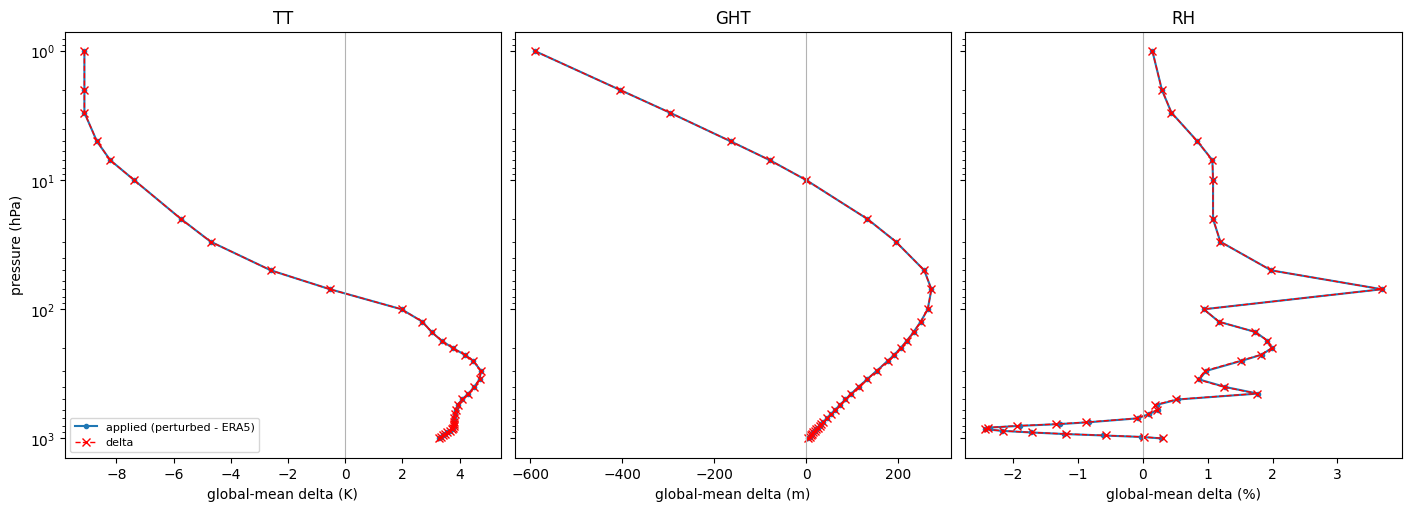

In [11]:
month0 = int(orig0[0].hdate[5:7])
lev_pa = deltas[month0]["lev_pa"]
weights = np.cos(np.deg2rad(lat))[:, None]  # cos(latitude) area weighting for the global mean

def applied_profile(field):
    """Area-weighted global mean of (perturbed - original) at every pressure level, for date0."""
    vals = []
    for lv in lev_pa:
        ro = find(orig0, field, lv)
        rp = find(pert0, field, lv)
        d = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)
        vals.append(np.average(d, weights=np.broadcast_to(weights, d.shape)))
    return np.array(vals)

def delta_profile(field):
    """Same area-weighted global mean, but straight from the stage-03 delta file -- the
    "ground truth" applied_profile() should reproduce if stage 04 applied it correctly."""
    d = deltas[month0][field].astype(np.float64)
    return np.array([np.average(d[i], weights=np.broadcast_to(weights, d[i].shape))
                      for i in range(d.shape[0])])

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True, constrained_layout=True)
for ax, field, xlabel in zip(axes, ["TT", "GHT", "RH"], ["K", "m", "%"]):
    # the two lines should sit right on top of each other if the perturbation was applied correctly
    ax.plot(applied_profile(field), lev_pa / 100, "o-", label="applied (perturbed - ERA5)", ms=3)
    ax.plot(delta_profile(field), lev_pa / 100, color="red", linestyle="--", marker="x",
            label="delta", lw=1)
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set_yscale("log")
    ax.invert_yaxis()  # pressure decreases upward -- put the surface at the bottom of the plot
    ax.set_xlabel(f"global-mean delta ({xlabel})")
    ax.set_title(field)
axes[0].set_ylabel("pressure (hPa)")
axes[0].legend(fontsize=8)
plt.show()

## 5. Physical sanity checks

In [12]:
# --- RH stays within [0, 100] everywhere after perturbation -----------------------------
# (04_apply_perturbation.py clips it there by design; this confirms the clip is doing its job)
for r in results:
    for rp in r["pert"]:
        if rp.field == "RH" and rp.xlvl != config.ERA5_SURFACE_LEVEL_PA:
            assert rp.slab.min() >= 0.0 and rp.slab.max() <= 100.0, \
                f"{r['date']} RH {rp.xlvl}: out of [0,100] range"
print("PASS: perturbed RH stays within [0, 100] at every level, every test date.")

# --- SST: land untouched, ocean warms, floor (271 K) never breached, not degenerate -----
d_sst = find(pert_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64) - \
        find(orig_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64)
ocean_mask = find(orig_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab > SST_FILL_THRESHOLD
pert_ocean_sst = find(pert_sst, "SST", config.ERA5_SURFACE_LEVEL_PA).slab
print(f"SST delta ({sst_date}, ocean only): mean={d_sst[ocean_mask].mean():+.2f} K, "
      f"min={d_sst[ocean_mask].min():+.2f} K, max={d_sst[ocean_mask].max():+.2f} K")
assert pert_ocean_sst[ocean_mask].min() >= SST_FLOOR_K - 1e-3, "SST floor was breached"
# 0-10 K is a generous but meaningful sanity bound for an ensemble-mean SSP370 warming signal --
# a value of 0 (no signal at all) or >10 K (an order of magnitude too large) would both indicate a bug
assert 0.0 < d_sst[ocean_mask].mean() < 10.0, "SST mean delta outside a physically plausible range"
print("PASS: SST warms over ocean, respects the 271 K floor, land untouched.")

# --- SKINTEMP warming is not degenerate (land tends to warm more than ocean SST) --------
d_skt = find(pert0, "SKINTEMP", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64) - \
        find(orig0, "SKINTEMP", config.ERA5_SURFACE_LEVEL_PA).slab.astype(np.float64)
print(f"SKINTEMP delta: mean={d_skt.mean():+.2f} K, min={d_skt.min():+.2f} K, max={d_skt.max():+.2f} K")
assert 0.0 < d_skt.mean() < 15.0, "SKINTEMP mean delta outside a physically plausible range"

# --- expected vertical structure: warming aloft in the free troposphere, cooling near the
#     stratosphere (standard climate-change signature: surface/troposphere warms as CO2 rises,
#     stratosphere cools as it radiates more efficiently to space) ------------------------
tt_profile = applied_profile("TT")
trop_mean = tt_profile[(lev_pa >= 50000) & (lev_pa <= 85000)].mean()  # 500-850 hPa
strat_mean = tt_profile[lev_pa <= 20000].mean()                       # <=200 hPa
print(f"TT delta: mid-troposphere (500-850 hPa) mean={trop_mean:+.2f} K, "
      f"lower-stratosphere (<=200 hPa) mean={strat_mean:+.2f} K")
assert trop_mean > 0, "expected tropospheric warming, got cooling"
assert strat_mean < trop_mean, "expected relative stratospheric cooling vs. tropospheric warming"
print("PASS: vertical structure matches the expected PGW signature "
      "(tropospheric warming, relative upper-level cooling).")

PASS: perturbed RH stays within [0, 100] at every level, every test date.
SST delta (1984-06-02_00, ocean only): mean=+1.93 K, min=-4.97 K, max=+6.20 K
PASS: SST warms over ocean, respects the 271 K floor, land untouched.
SKINTEMP delta: mean=+3.33 K, min=-4.88 K, max=+17.82 K
TT delta: mid-troposphere (500-850 hPa) mean=+3.85 K, lower-stratosphere (<=200 hPa) mean=-3.36 K
PASS: vertical structure matches the expected PGW signature (tropospheric warming, relative upper-level cooling).


## 6. SST-update stream (`ERA5_SST:*` -> `SST_UPDATE:*`) verification

The periodic SST-update stream is a separate file layout from the main `ERA5:*` archive: `config.ERA5_IM_DIR/SST_<year>/ERA5_SST:<date>`, one record per file. This stream differs from the main-stream `SST` record in two ways:

- **Field name is inconsistent across years** (some years label the record `SST`, others `SKINTEMP`) even though it's always sea-surface temperature -- stage 04 dispatches on which *file* it is, not the record's field name. Checked below by asserting the on-disk field name is unchanged by perturbation.
- **No land-fill sentinel** -- land grid points here hold real (non-sentinel) skin-temperature values, so stage 04 uses a static `LANDSEA`-derived ocean mask instead (`apply_pgw.load_ocean_mask()`), reused directly here rather than reimplemented.

All SST-update test dates are auto-discovered from `PERT_DIR`, spanning however much of the year stage 04 actually processed -- for the `--years 1984` test run this is nearly the full year, not just a handful of June days, so the plausibility check below is a much stronger, near-annual test of the SST warming signal than the main-stream spot check above.

In [13]:
# Static geography -- read once from any main-stream ERA5:* file's LANDSEA record and reused
# for every SST-update date, since land/ocean doesn't change day to day.
ocean_mask_sst = apply_pgw.load_ocean_mask()
print("ocean fraction (LANDSEA-derived mask):", ocean_mask_sst.mean())

def orig_path_for_sst_update(pert_path):
    """Map a perturbed SST_UPDATE:<date> path back to its ERA5_SST:<date> original --
    stage 04 renames the prefix on write (see 04_apply_perturbation.py's docstring), so
    inverting that rename is how we find the file each perturbed one came from."""
    orig_name = apply_pgw._SST_UPDATE_SRC_PREFIX + pert_path.name[len(apply_pgw._SST_UPDATE_PREFIX):]
    rel_dir = pert_path.parent.relative_to(PERT_DIR)  # e.g. "SST_1984", same on both sides
    return ORIG_DIR / rel_dir / orig_name

def check_sst_update_file(pert_path):
    orig_path = orig_path_for_sst_update(pert_path)
    date = pert_path.name.split(":")[1]
    orig = wps.read_file(orig_path)
    pert = wps.read_file(pert_path)
    assert len(orig) == 1 and len(pert) == 1, f"{date}: expected exactly 1 record"
    ro, rp = orig[0], pert[0]
    # the on-disk field name ("SST" some years, "SKINTEMP" others) must be preserved as-is --
    # renaming it would mean stage 04 mishandled the year-to-year naming inconsistency
    assert ro.field == rp.field, f"{date}: field name changed by perturbation ({ro.field} -> {rp.field})"
    assert (ro.nx, ro.ny) == (config.ERA5_NX, config.ERA5_NY), f"{date}: unexpected grid size"

    land = ~ocean_mask_sst
    land_untouched = np.array_equal(ro.slab[land], rp.slab[land])
    return dict(date=date, field=ro.field, orig=ro, pert=rp, land_untouched=land_untouched)

sst_update_results = [check_sst_update_file(f) for f in sst_pert_files]
n_fail = sum(1 for r in sst_update_results if not r["land_untouched"])
print(f"{len(sst_update_results)} SST-update files checked, {n_fail} with land cells modified")
if n_fail:
    for r in sst_update_results:
        if not r["land_untouched"]:
            print("  FAIL:", r["date"])

assert all(r["land_untouched"] for r in sst_update_results), \
    "an SST-update file's land cells were modified -- should never happen"
print("\nPASS: every SST-update test file's land cells (per the static LANDSEA mask) are "
      "byte-identical to the original; only ocean cells were perturbed.")

ocean fraction (LANDSEA-derived mask): 0.6611111111111111
184 SST-update files checked, 0 with land cells modified

PASS: every SST-update test file's land cells (per the static LANDSEA mask) are byte-identical to the original; only ocean cells were perturbed.


In [14]:
def cross_check_sst_update(r):
    """Same idea as section 2's cross_check(), specialized for the single-record
    SST-update file layout and its LANDSEA-derived (not fill-sentinel-derived) ocean mask."""
    ro, rp = r["orig"], r["pert"]
    month = int(rp.hdate[5:7])
    applied = rp.slab.astype(np.float64) - ro.slab.astype(np.float64)
    expected = deltas[month]["SST"].astype(np.float64)

    # only compare ocean cells that didn't hit the 271 K floor -- floored cells are checked separately below
    not_floored = rp.slab > apply_pgw.SST_FLOOR_K
    cmp_mask = ocean_mask_sst & not_floored
    err = np.abs(applied - expected)[cmp_mask]

    floored = ocean_mask_sst & ~not_floored
    if floored.any():
        assert np.allclose(rp.slab[floored], apply_pgw.SST_FLOOR_K), \
            f"{r['date']}: SST-update floor-clamped cells not at {apply_pgw.SST_FLOOR_K} K"
    return float(err.max()) if err.size else 0.0

# only cross-check dates whose month has a stage-03 delta file loaded (months_needed, section 2)
sst_update_errs = {r["date"]: cross_check_sst_update(r) for r in sst_update_results
                   if int(r["pert"].hdate[5:7]) in deltas}

worst_sst_update = max(sst_update_errs.values(), default=0.0)
print(f"worst-case |applied - stage03 SST delta| across {len(sst_update_errs)} SST-update test files: "
      f"{worst_sst_update:.4g}")
assert worst_sst_update < 1e-2, "SST-update perturbation does not match the stage-03 delta"
print("PASS: SST-update files match the stage-03 SST delta within float32 tolerance.")

worst-case |applied - stage03 SST delta| across 30 SST-update test files: 1.526e-05
PASS: SST-update files match the stage-03 SST delta within float32 tolerance.


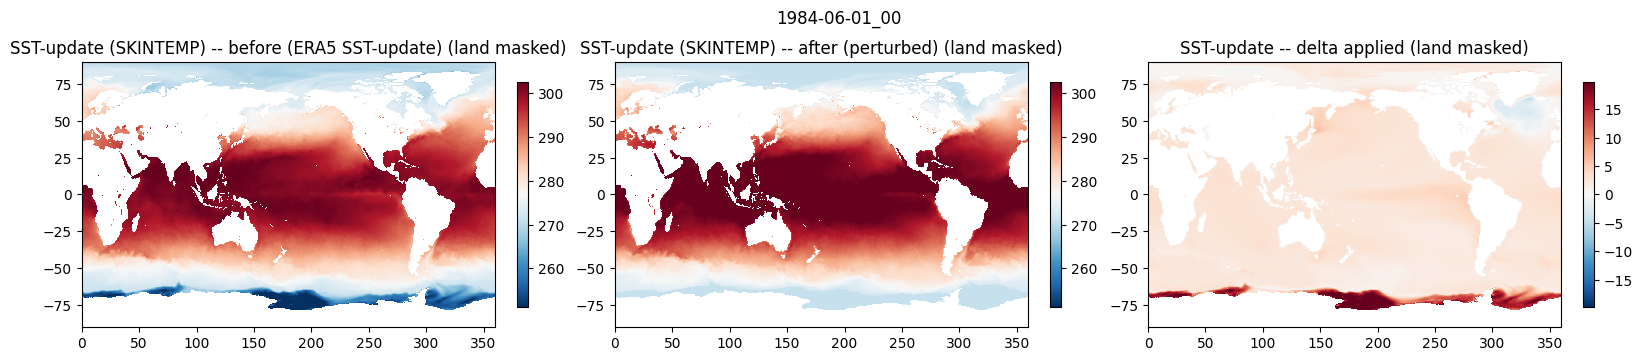

In [15]:
# One representative SST-update date, same before/after/diff map style as section 3.
r0 = sst_update_results[0]
ro, rp = r0["orig"], r0["pert"]
land = ~ocean_mask_sst
before = np.where(land, np.nan, ro.slab)
after = np.where(land, np.nan, rp.slab)
d = np.where(land, np.nan, rp.slab.astype(np.float64) - ro.slab.astype(np.float64))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
vmin, vmax = np.nanpercentile(before, [1, 99])
for ax, data, title in zip(axes[:2], [before, after], ["before (ERA5 SST-update)", "after (perturbed)"]):
    im = ax.pcolormesh(lon, lat, data, vmin=vmin, vmax=vmax, cmap="RdBu_r", shading="auto")
    ax.set_title(f"SST-update ({r0['field']}) -- {title} (land masked)")
    fig.colorbar(im, ax=ax, shrink=0.85)
dmax = np.nanpercentile(np.abs(d), 99)
im = axes[2].pcolormesh(lon, lat, d, vmin=-dmax, vmax=dmax, cmap="RdBu_r", shading="auto")
axes[2].set_title("SST-update -- delta applied (land masked)")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.suptitle(f"{r0['date']}", y=1.08)
plt.show()

In [16]:
# Aggregate ocean-only delta across every SST-update test date (not just the one date plotted
# above) -- with ~a full year of daily files this is a much stronger statistical check than a
# single-day snapshot.
d_all = np.concatenate([
    (r["pert"].slab.astype(np.float64) - r["orig"].slab.astype(np.float64))[ocean_mask_sst]
    for r in sst_update_results
])
print(f"SST-update delta (ocean only, all {len(sst_update_results)} test dates): "
      f"mean={d_all.mean():+.2f} K, min={d_all.min():+.2f} K, max={d_all.max():+.2f} K")
assert 0.0 < d_all.mean() < 10.0, "SST-update mean delta outside a physically plausible range"

for r in sst_update_results:
    assert r["pert"].slab[ocean_mask_sst].min() >= apply_pgw.SST_FLOOR_K - 1e-3, \
        f"{r['date']}: SST-update floor breached"

print("PASS: SST-update stream warms over ocean, respects the 271 K floor, land untouched, "
      "consistent across all test dates.")

# A single grid cell warming far more than the mean is worth a look but isn't automatically a
# bug -- e.g. a cell where the raw archived "SST" is an unphysically cold under-ice value will
# show a large (perturbed - original) simply because the 271 K floor pulls it up to a sane
# value, which is the floor doing its job, not the delta being wrong. Flag rather than hide it:
outlier_thresh = 20.0
n_outliers = int((d_all > outlier_thresh).sum())
if n_outliers:
    print(f"\nNOTE: {n_outliers} of {d_all.size} ocean-cell/date combinations show a delta > "
          f"{outlier_thresh:.0f} K (max {d_all.max():.1f} K) -- likely isolated cases where the "
          "271 K floor corrected an already-anomalous raw ERA5 value (e.g. under permanent sea "
          "ice), not a perturbation bug; worth a quick map check if this fraction grows.")

SST-update delta (ocean only, all 184 test dates): mean=+3.33 K, min=-5.31 K, max=+47.01 K
PASS: SST-update stream warms over ocean, respects the 271 K floor, land untouched, consistent across all test dates.

NOTE: 1973538 of 126296128 ocean-cell/date combinations show a delta > 20 K (max 47.0 K) -- likely isolated cases where the 271 K floor corrected an already-anomalous raw ERA5 value (e.g. under permanent sea ice), not a perturbation bug; worth a quick map check if this fraction grows.


## Summary

- **Structural integrity**: every main-stream test file touches exactly the expected records and nothing else. Every other field/record, including the 2 m `TT`/`RH` surface-sentinel records and everything not in the perturbation set, is byte-identical to the original.
- **Quantitative correctness**: `perturbed - original` matches the stage-03 delta file within float32 round-trip tolerance at every level, for every test date -- including `SST` (ocean-only, floor-respecting). The only deviations from an exact match are precisely where the documented RH `[0, 100]` clip and SST 271 K floor apply.
- **Physical plausibility**: the applied delta reproduces the expected PGW pattern -- tropospheric warming with geopotential expansion, weakening/reversing toward the tropopause, ocean (SST) and land (SKINTEMP) surface warming -- now driven by the 10-member LENS2 ensemble mean rather than a single member.
- **SST-update stream**: on-disk field naming is preserved exactly; only ocean cells (per the static `LANDSEA`-derived mask, reused directly from `04_apply_perturbation.load_ocean_mask()`) are modified; the applied delta matches the stage-03 `SST` field within float32 tolerance; the 271 K floor is respected; ocean warms by a physically plausible amount across the full span of test dates actually produced.

This notebook auto-discovers its test set from `config.PERTURBED_IM_DIR`, so re-running it after `04_apply_perturbation.py` processes more years/months verifies the new output without any edits here.